# Astroquery examples

<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) European Space Agency, 2026.

This file is subject to the terms and conditions defined in file LICENSE.txt, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file LICENSE.txt.

</div>

**Last modified:** 2026-11-11

**Last update:** Update ADQL query examples for DR1-Foundation.

**Notebook summary**

This notebook includes the ADQL Query examples that are directly accessible from the Euclid Archive WEB interface.

1. To facilitate the navigation through this notebook, only the first 3 lines of the retrieved tables are displayed when the downloaded table contains > 10 rows. This can be easily adjusted or modified below.
2. The ADQL queries are designed to not exceed 1 minute execution time. Currently, most queries are finished in <5 seconds, but their execution time once PDR is public will increase.
3. the ADQL queries are set using the [Python f-string](https://docs.python.org/3/tutorial/inputoutput.html). This approach improves the user experience as it allows to easily modify the optional parts of the query. At the same time, I have tried to not "abuse" of this utility to balance the readibility and interactivity of the examples.

**Some useful links:**
* [Euclid DR1 data product description](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [Euclid DR1 ](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Astroquery.Euclid documentation content](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)
* [Astroquery.EuclidClass help content](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass)
* [Astropy table documentation](https://docs.astropy.org/en/stable/table/index.html)
* [Gaia Archive: TAP and ADQL](https://www.cosmos.esa.int/web/gaia-users/archive/writing-queries)

**Running the notebook:** This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example. The notebook is intended to be run using the **EUCLID-TOOLS kernel** that has all the necessary packages included.

In [1]:
#installing necessary packages
from astroquery.esa.euclid.core import Euclid

from astropy import wcs
import pandas as pd
import astropy.units as u
from astropy.nddata.utils import Cutout2D
from astropy.coordinates import SkyCoord
from astroquery.simbad import Simbad
from astropy.table import Table

from astropy.io import fits
import matplotlib.pyplot as plt
from astropy.visualization import astropy_mpl_style, ImageNormalize, PercentileInterval, AsinhStretch, LogStretch
plt.style.use(astropy_mpl_style)
import os
import getpass

First let's make a folder (if not already created) to save the output files from this notebook. All the example notebooks save their outputs to this same folder in your user workspace called: `'example_notebook_outputs/'`

In [2]:
#making a folder for the output files
output_folder= '/media/user/example_notebook_outputs/'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

**Please note:** When comparing the Q1 and DR1-foundation data releases:
* some table and column names will be different
* specific example source coordinates

It is possible to login using many different options - see the # [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) method for details. Similarly to the archive website for safety reasons this login expires after a period of time. Once this happens the queries to the archive will fail (seemingly without reason). If you are running a personal notebook that requires you to stay logged in for longer - make sure to execute this code line again every once in a while. 

In [3]:
# Alternative ways to login; uncomment your preferred one: ===========
Euclid.login()
# Euclid.login_gui()                                          # Login via graphic interface (pop-up window)
# Euclid.login(user='<user name>', password='<password>')     # 
# Euclid.logout()

INFO: Login to Euclid TAP server: eas.esac.esa.int:443/tap-server/tap/ [astroquery.esa.euclid.core]


User:  hcanovas
Password:  ········


INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid data service: eas.esac.esa.int:443/sas-dd/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid cutout service: eas.esac.esa.int:443/sas-cutout/tap-server/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]
INFO: Login to Euclid sia service: eas.esac.esa.int:443/sas-sia/ [astroquery.esa.euclid.core]
INFO: OK [astroquery.utils.tap.core]


In [4]:
schema = 'dr1'   # DR1 schema. Change to "q1" to retrieve Q1 data, but please note that the target table names should be adapted accordingly. 

## 1. Loading tables

### 1.1 load_tables - Load all public data tables metadata

The [load_tables](https://astroquery.readthedocs.io/en/latest/api/astroquery.utils.tap.TapPlus.html#astroquery.utils.tap.TapPlus.load_tables) method returns a list of table (objects) hosted by the Archive.

In [5]:
tables = Euclid.load_tables(only_names=True, include_shared_tables=True)
print(f'* Found {len(tables)} tables')

for table in (tables[0:5]):                # Remove the "[0:5]" to list all the public tables
    print(table.get_qualified_name())

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]
* Found 203 tables
dr1.mer_catalogue_deep_mode
dr1.mer_catalogue_deep_mode_photometry
dr1.mer_cutouts_deep_mode
dr1.mer_morphology_deep_mode
dr1.mer_catalogue_deep_survey


### 2.2 load_table - Load metadata for a specified table

If the user is logged in, the table can refer to a table in the user's private area. The method returns a tap table metadata object.

| Input parameter | Type | Mandatory | Default | Description |
| --- | --- | --- | --- | --- |
| table | str | yes| - | Full qualified table name (i.e. schema name + table name)
| verbose | bool | no | False | Flag to display information about the process 

In [6]:
# Getting all columns for the {schema}.calibrated_frame table
table = Euclid.load_table(table=f"{schema}.calibrated_frame", verbose=False)
print(table)
print()
print('Columns: ')
for column in table.columns[0:5]:                # Remove the "[0:5]" to list all the public tables
    print(f' * {column.name}')

TAP Table name: dr1.calibrated_frame
Description: None
Size (bytes): 0
Num. columns: 41

Columns: 
 * activity_code
 * calibrated_frame_oid
 * category
 * creation_date
 * datalabs_path


## 2. Cone search


The [cone_search](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.cone_search) method implements one of the most common use cases when interacting with an astronomy archive: retrieving data within a circular region on the sky, centered on a given position, from a specified catalogue. The example below demonstrates how to perform a cone search with a radius of 0.1 degrees around NGC 6505. By default, the method: 1) queries the mer_catalogue_deep_survey, 2) 
limits the output to 50 rows, and 3) returns all available columns from the target catalogue. For better performance, we strongly recommend selecting only the columns of interest, as this can significantly reduce query execution time. The row limit can be disabled by setting the ROW_LIMIT attribute to -1 (see the following example).

In [7]:
# selecting source coordinates based on chosen archive env (to make sure source exists)
coords        = SkyCoord.from_name('NGC 6505')
print(f'* Target coords: {coords}')

* Target coords: <SkyCoord (ICRS): (ra, dec) in deg
    (267.7808542, 65.5307778)>


In [8]:
radius  = u.Quantity(0.1, u.deg)
columns = ['designation', 'object_id', 'patch_id_list', 'tile_index', 'right_ascension', 'declination', 'flux_detection_total', 'flux_vis_sersic', 'segmentation_area']
job     = Euclid.cone_search(coordinate=coords, radius=radius, table_name=f'{schema}.mer_catalogue_deep_survey', columns = columns, async_job=True)

res    = job.get_results()
print(f"* Found {len(res)} results")
res[:3]   # Remove the "[0:3]" to visualise the full job output.

INFO: Query finished. [astroquery.utils.tap.core]
* Found 50 results


designation,object_id,patch_id_list,tile_index,right_ascension,declination,flux_detection_total,flux_vis_sersic,segmentation_area,dist
,NA,,,deg,deg,uJy,uJy,pix,
object,int64,int64[8],int64,float64,float64,float64,float64,int32,float64
Euclid DR1 J175107.515+653151.62,2677813145655310071,38 .. 114,101832848,267.7813145427671,65.53100719954608,23316.30859375,23300.837890625,1209575,0.0002940536164260755
Euclid DR1 J175110.286+653212.76,2677928616655368778,38 .. 114,101832848,267.79286160946873,65.53687789461725,2328.321533203125,2665.15283203125,83737,0.007865984420393213
Euclid DR1 J175105.790+653113.18,2677741285655203280,38 .. 114,101832848,267.7741285989949,65.52032802520502,639.3799438476562,805.5308837890625,37203,0.010820149996037521


In [9]:
table_name       = f'{schema}.calibrated_frame'
radius           = u.Quantity(0.2, u.deg)
Euclid.ROW_LIMIT = -1               # Set this attribute to -1 to retrieve the full output of the cone_search method.
job              = Euclid.cone_search(coordinate='NGC 6505', radius=radius, table_name=table_name, ra_column_name="ra", dec_column_name="dec", async_job=True, columns = ['file_name', 'datalabs_path', 'file_path', 'ra', 'dec', 'patch_id', 'start_time'], output_format = 'votable')
res              = job.get_results()
print(f"* Found {len(res)} results")
res[0:2]

INFO: Query finished. [astroquery.utils.tap.core]
* Found 36 results


file_name,datalabs_path,file_path,ra,dec,patch_id,start_time,dist
,,,deg,deg,,,
object,object,object,float64,float64,int64,object,float64
EUC_VIS_SWL-DET-004996-00-2-0000000__20250615T052311.277130Z.fits,/data/euclid_idr1/DR1/R1/VIS_QUAD/4996,/data/euclid/repository_dr1/DR1/R1/VIS_QUAD/4996,267.50661173,65.54138497,--,2024-11-28T16:54:16.747,0.1140631271377365
EUC_VIS_SWL-DET-004996-00-1-0000000__20250615T052311.085617Z.fits,/data/euclid_idr1/DR1/R1/VIS_QUAD/4996,/data/euclid/repository_dr1/DR1/R1/VIS_QUAD/4996,267.50661173,65.54138497,--,2024-11-28T16:39:33.746,0.1140631271377365


**Notes:**

* Once the table_name, ra_column_name, and dec_column_name arguments are set by the user, the method does not recognise the default values. This is a known issue.
* Users are stronlgy adviced to use the [cone_search](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.cone_search) method instead of the [query_object](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.query_object) method. The latter makes use of the ADQL BOX function that is deprecated
and can yield misleading results due to a geometric projection effect.

## 3. Launching jobs

### 3.1 Synchronous query

This is the recommended mode for queries that do not require excesive computation time and/or that generate relatively small results - for details please see [this Gaia Archive FAQ](https://www.cosmos.esa.int/web/gaia/faqs#account-limits-2026). This function is implemented by the [launch_job](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.launch_job) method.
Note that:
* The output of sync queries is limited to 2,000 rows if the query execution time exceeds 30(60) seconds for anonymous (registered) users.
* The job result ("res") below is an [Astropy table](https://docs.astropy.org/en/stable/table/index.html) object. The example shows how to store it locally in [VOTable](https://www.ivoa.net/documents/VOTable/20250116/) format.

**Note that the names of tables may change between different archive environments**

In [10]:
table_name=f'{schema}.mer_catalogue_deep_survey'

query = f"SELECT designation, object_id, right_ascension, declination, tile_index, ellipticity, kron_radius FROM {table_name} WHERE ellipticity > 0"
print(query)
job   = Euclid.launch_job(query)
res   = job.get_results()
print(f'* Output table contains {len(res)} rows')

res[0:3]

SELECT designation, object_id, right_ascension, declination, tile_index, ellipticity, kron_radius FROM dr1.mer_catalogue_deep_survey WHERE ellipticity > 0
* Output table contains 2000 rows


designation,object_id,right_ascension,declination,tile_index,ellipticity,kron_radius
,NA,deg,deg,,NA,pix
object,int64,float64,float64,int64,float64,float64
Euclid DR1 J173038.519+663746.27,2626604995666295208,262.66049952453136,66.6295208911116,101835778,0.1468677669763565,35.79146957397461
Euclid DR1 J173001.026+663751.81,2625042767666310577,262.50427671215385,66.63105779633491,101835778,0.0712171271443367,9.747993469238281
Euclid DR1 J172940.748+663821.91,2624197872666394209,262.4197872473342,66.63942092972908,101835778,0.23378124833106995,9.937935829162598


### 3.2. launch_job_async - Make an asynchronous query

This is the recommended mode for queries that are expected to output more than 2,000 rows and that require substantial execution time (noting that all the queries time out after 7200 seconds), and in this package it is implemented by the
[launch_job_async](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.launch_job_async) method. The query results are stored in the Archive (during 72 hours for anonymous users, and on the user area until the user deletes them for registered users). 
The example below generates a cone search combined with a constraint applied to the ellipticity, and is similar to the first ADQL query example listed in the [Euclid Archive](https://eas.esac.esa.int/sas/) (see its "Search/ADQL FORM" subtab).
For more ADQL examples please have a look at the Gaia Archive Help content (in particular, the [writting queries](https://www.cosmos.esa.int/web/gaia-users/archive/writing-queries) section).

Note: It is a good practise to - from time to time - remove all jobs from the user space. The Gaia Archive FAQ [Is it possible to delete all the jobs (or a selection of them) in my job list at once?](https://www.cosmos.esa.int/web/gaia/faqs#delete-jobs-2020) shows how to do this programmatically - In the example code, simply replace "Gaia" by "Euclid" where needed.

In [11]:
query = f"""SELECT right_ascension, declination, designation, object_id, vis_det, det_quality_flag, flux_detection_total, flux_vis_sersic, segmentation_area, kron_radius, DISTANCE(267.78, 65.53, right_ascension, declination) AS dist
FROM {table_name}
WHERE DISTANCE(267.78, 65.53, right_ascension, declination) < 0.1 AND
ellipticity > 0"""
print(f' * Launching ADQL query: ')
print(query)

job   = Euclid.launch_job_async(query, verbose=False, output_format = 'votable')
print(job)  # This prints the job metadata (like "JObID", "Phase", "Owner", ...)

res   = job.get_results()
print(f"Found {len(res)} query results")
res[0:3]

 * Launching ADQL query: 
SELECT right_ascension, declination, designation, object_id, vis_det, det_quality_flag, flux_detection_total, flux_vis_sersic, segmentation_area, kron_radius, DISTANCE(267.78, 65.53, right_ascension, declination) AS dist
FROM dr1.mer_catalogue_deep_survey
WHERE DISTANCE(267.78, 65.53, right_ascension, declination) < 0.1 AND
ellipticity > 0
INFO: Query finished. [astroquery.utils.tap.core]
<Table length=24319>
        name          dtype  unit                                                       description                                                       n_bad
-------------------- ------- ---- ----------------------------------------------------------------------------------------------------------------------- -----
     right_ascension float64  deg                                                Source barycenter RA coordinate (SExtractor ALPHA_J2000) decimal degrees     0
         declination float64  deg                                               S

right_ascension,declination,designation,object_id,vis_det,det_quality_flag,flux_detection_total,flux_vis_sersic,segmentation_area,kron_radius,dist
deg,deg,,NA,NA,NA,uJy,uJy,pix,pix,
float64,float64,object,int64,int16,int16,float64,float64,int32,float64,float64
267.76536648649414,65.43810225034346,Euclid DR1 J175103.687+652617.17,2677653664654381022,1,2,7.392856121063232,7.536567211151123,333,13.514887809753418,0.0920981377589544
267.68913903645335,65.43948375142209,Euclid DR1 J175045.393+652622.14,2676891390654394837,1,384,0.24832580983638763,0.15620261430740356,38,19.5548038482666,0.09805399203212296
267.7074648141822,65.44225921285364,Euclid DR1 J175049.791+652632.13,2677074648654422592,1,256,0.797406017780304,0.39134520292282104,84,37.63509750366211,0.09275883692358879


## 4. Getting products

In addition to catalogues that can be queried via [ADQL](https://www.ivoa.net/documents/ADQL/20231215/index.html), the Euclid Archive also host the Euclid products: the FITS files that contain the different types or products (images, spectra, catalogues) generated by this mission. A popular use case is "I want to download the Euclid image of my favourite object". In order to do this, one must know the coordinates of the selected object, the instrument that was used to acquire the observation, and the type of product (e.g. raw, calibrated, mosaic, ...) that one wants to inspect. In the next example we proceed in two steps (see below).

**Step 1:**

First, we query the "mosaic_product" TAP table that contains the names of the FITS files with the background-subtracted mosaic images (associated with the Euclid product: [DpdMerBksMosaic](http://st-dm.pages.euclid-sgs.uk/data-product-doc/dmdr1/merdpd/dpcards/mer_bksmosaic.html)) and their sky coverage (in its "fov" field). For this example we are targeting the images that include observations that cover the coordinates of NGC 6505. In the query below note:

1. the use of the "instrument_name" field to only select "VIS" observations, 
2. the radius variable that indicates the minimum distance between the target coordinates and the edges of the images, and
3. the use of the INTERSECTS ADQL clause in combination with the CIRCLE function. The target coordinates correspond to NGC 6505.

Note the "ORDER BY" clause applied to the "tile_index" field. If there are multiple observations that contain the target in their field of view (as in the example below), then the observations with the smaller tile_index are the ones where the target is located closer to the observation centre. 

In [12]:
# Target selection: ==================================================================================
coords        = SkyCoord.from_name('NGC 6505')
radius        = 0.5/60.                                                                              # This radius indicate the minimum distance between the target coordinates and the image edges.
table_name    = f'{schema}.mosaic_product'


# ADQL query =========================================================================================
query     = f"""SELECT file_name, file_path, datalabs_path, instrument_name, filter_name, ra, dec, creation_date, product_type, patch_id_list, tile_index
FROM {table_name}
WHERE instrument_name = 'VIS' AND
datalabs_path IS NOT NULL AND 
INTERSECTS(CIRCLE({coords.ra.deg:3.4f}, {coords.dec.deg:3.4f}, {radius:3.4f}), fov)=1
ORDER BY tile_index"""

print(f'* Launching ADQL query: ')
print(query)

job = Euclid.launch_job_async(query, output_format = 'votable')
res = job.get_results()
res[0:3] # Display only top 3 rows to reduce verbosity

* Launching ADQL query: 
SELECT file_name, file_path, datalabs_path, instrument_name, filter_name, ra, dec, creation_date, product_type, patch_id_list, tile_index
FROM dr1.mosaic_product
WHERE instrument_name = 'VIS' AND
datalabs_path IS NOT NULL AND 
INTERSECTS(CIRCLE(267.7809, 65.5308, 0.0083), fov)=1
ORDER BY tile_index
INFO: Query finished. [astroquery.utils.tap.core]


file_name,file_path,datalabs_path,instrument_name,filter_name,ra,dec,creation_date,product_type,patch_id_list,tile_index
object,object,object,object,object,float64,float64,object,object,object,int64
EUC_MER_BGSUB-MOSAIC-VIS_TILE101832848-89A871_20250828T201044.997028Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/101832848/VIS,/data/euclid_idr1/DR1/R1/MER/101832848/VIS,VIS,VIS,267.5203511539,65.5,2025-08-29T22:02:21.92,DpdMerBksMosaic,"38,39,44,49,57,64,99,114,130,151,171",101832848
EUC_MER_BGSUB-MOSAIC-VIS_TILE101832849-10FC32_20250829T222309.224544Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/101832849/VIS,/data/euclid_idr1/DR1/R1/MER/101832849/VIS,VIS,VIS,268.1174947948,65.5,2025-08-30T19:40:21.926,DpdMerBksMosaic,"38,39,44,49,57,64,99,114,130,151,171",101832849
EUC_MER_BGSUB-MOSAIC-VIS_TILE102158889-DDD984_20250711T142958.432200Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/102158889/VIS,/data/euclid_idr1/DR1/R1/MER/102158889/VIS,VIS,VIS,267.3807789,65.4983,2025-07-12T19:57:48.569,DpdMerBksMosaic,116,102158889


**Step 2:**

Access to the image using the "datalabs_path" and "file_name" information. Note that to speed up the rendering of the image, an undesampling factor of 10x is applied in the code below.

Reading: /data/euclid_idr1/DR1/R1/MER/101832848/VIS/EUC_MER_BGSUB-MOSAIC-VIS_TILE101832848-89A871_20250828T201044.997028Z_00.00.fits


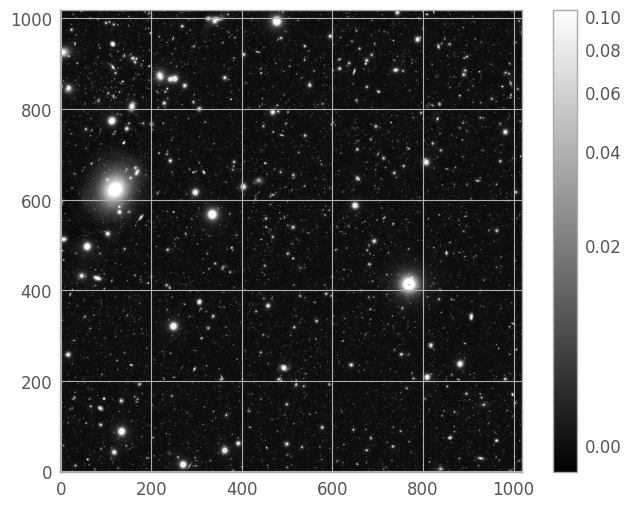

In [13]:
path_to_fits = f"{res['datalabs_path'][0]}/{res['file_name'][0]}"
hdul         = fits.open(path_to_fits)
print(f'Reading: {path_to_fits}')

image_data = hdul[0].data[::10, ::10]

plt.figure()
plt.imshow(image_data, cmap='gray', origin='lower', norm=ImageNormalize(image_data, interval=PercentileInterval(99.1), stretch=AsinhStretch()))
colorbar = plt.colorbar()
hdul.close()

# To export the image as png:
# png_name = path_to_fits[path_to_fits.rfind('/')+1:].replace('.fits','.png')
# plt.savefig(png_name, dpi=300, bbox_inches='tight', pad_inches=0)

## 6. Making MER cutouts


In many situations, users are only interested in downloading a small portion of the MER (background subtracted) Euclid image. The [get_cutout](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.get_cutout) method addresses this particular case, as it allows to download image cutouts and store them locally. For reference, downloading a 1'x1'cutout takes less than one second and the downloaded fits file weights ~5.5 MB.


**Note:** This method uses the astroquery cutout service to download a cutout fits image from the Archive, and it only works for MER images. The example below takes advantage of the Euclid data (FITS files) that are directly accessible from ESA Datalabs (no download needed). See also the dedicated [Cutouts_v2.ipynb](Cutouts_v2.ipynb) notebook that shows how to create cutouts from different types of Euclid images.

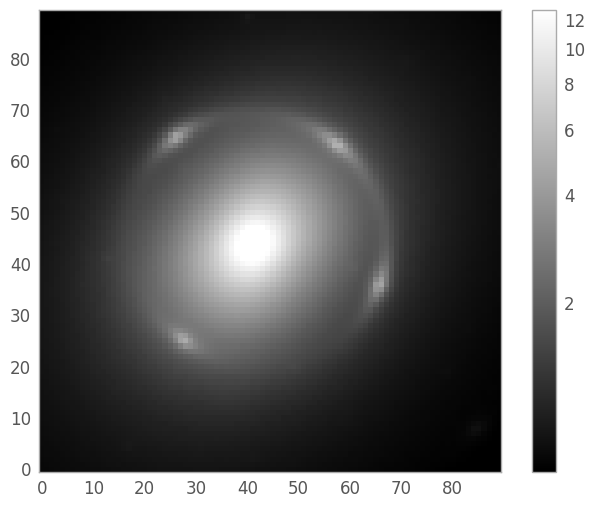

In [14]:
# Retrieve cutout ==============
file_path  = f"{res['datalabs_path'][0]}/{res['file_name'][0]}"

cutout_r      = 0.15 * u.arcmin 
hdul          = fits.open(file_path)
data          = hdul[0].data
header        = hdul[0].header
cutout_VIS    = Cutout2D(data=data, position = coords, size= cutout_r, wcs=wcs.WCS(header))


# Plot image ===================
plt.figure()
plt.imshow(cutout_VIS.data, cmap='gray', origin='lower', norm=ImageNormalize(cutout_VIS.data, interval=PercentileInterval(99.1), stretch=AsinhStretch()))
colorbar = plt.colorbar()
plt.grid(False)
hdul.close()

# To export the image as png:
# png_name = 'cutout_example.png'
# plt.savefig(png_name, dpi=300, bbox_inches='tight', pad_inches=0)

## 7. Spectra access

From the WEB GUI interface, the spectra is served via the [DataLink](https://www.ivoa.net/documents/DataLink/20231215/index.html) data access protocol that is compliant with the [IVOA](https://www.ivoa.net/) architecture. It provides a linking mechanism between datasets offered by different services. In practice, it can be seen and used as a web service providing the list of additional data products available for each object outside the main catalogue(s). For more information about the products served via DataLink in the [Euclid ESA Archive](https://eas.esac.esa.int/sas/), we recommend reading the Archive DataLink tutorials available at the Archive Help content (see the [Access to spectra](https://s2e2.cosmos.esa.int/www/ek_iscience/Access_to_spectra.html) section). In the Archive the 1D Spectra data (noting that in Euclid Q1 only the blue part of the spectra is available) is served via the [DataLink](https://www.ivoa.net/documents/DataLink/20231215/index.html) service. 

From Datalabs, it is possible to directly read the FITS files with the spectra without having to download them, as explained below. Either case (via [DataLink](https://www.ivoa.net/documents/DataLink/20231215/index.html) or using Datalabs), 
a two-step approach (as it happens with the Euclid products detailed in Sect. 5 and 6 above) is needed to access to this product. An example using this access mode is shown below, where the specra associated to the bright AGN [[SIK2013] J175514.9+663851.4](https://simbad.cds.unistra.fr/simbad/sim-basic?Ident=%5BSIK2013%5D+J175514.9%2B663851.4&submit=SIMBAD+search) is retrieved.

**Step 1:** 

First, you need to know the sources that have associated spectra. This information is included in the spectra_source table that can be accessed as follows:

In [15]:
radius           = u.Quantity(0.1, u.arcmin)
Euclid.ROW_LIMIT = -1               # Set this attribute to -1 to retrieve the full output of the cone_search method.
job              = Euclid.cone_search(coordinate='[SIK2013] J175514.9+663851.4', radius=radius, table_name=f'{schema}.spectra_source', ra_column_name="ra_obj", dec_column_name="dec_obj", async_job=True, columns = '*', output_format = 'ecsv')

res              = job.get_results()
print(f"* Found {len(res)} results")
res[0:2]

INFO: Query finished. [astroquery.utils.tap.core]
* Found 19 results


calblock_id_list,combined_spectra_fk,combined_spectra_product_fk,datalabs_path,dec_obj,dith_num,file_name,file_path,hdu_index,lambda_range,patch_id_list,ra_obj,source_id,sourcepatch_id,spectra_source_oid,to_be_published,dist
object,int64,int64,str55,float64,int64,str57,str65,int64,str3,int64,float64,int64,object,int64,int32,float64
['CALBLOCK-F-003'],6206,506809,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475957444824,3,EUC_SIR_W-COMBSPEC_102159486_20250823T144410.742623Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,804,RGS,99,268.812408005527,2688124080666475957,['268812408066647595799'],117140596,1,9.766042680420095e-05
['CALBLOCK-F-003'],6088,494875,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475992519604,4,EUC_SIR_W-COMBSPEC_102159486_20250823T152148.236419Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,785,RGS,151,268.812411149428,2688124111666475992,['2688124111666475992151'],114174169,1,9.820313870845445e-05


**Step 2 (direct access to the spectra):** 

Access to the image using the "datalabs_path", "file_name", and "hdu_index" information. In this case, we recommend to first open the Multi-extension fits file with the [Astropy fits](https://docs.astropy.org/en/stable/io/fits/index.html) package, and convert the data to an [Astropy table](https://docs.astropy.org/en/stable/table/index.html) object to handle it easier.


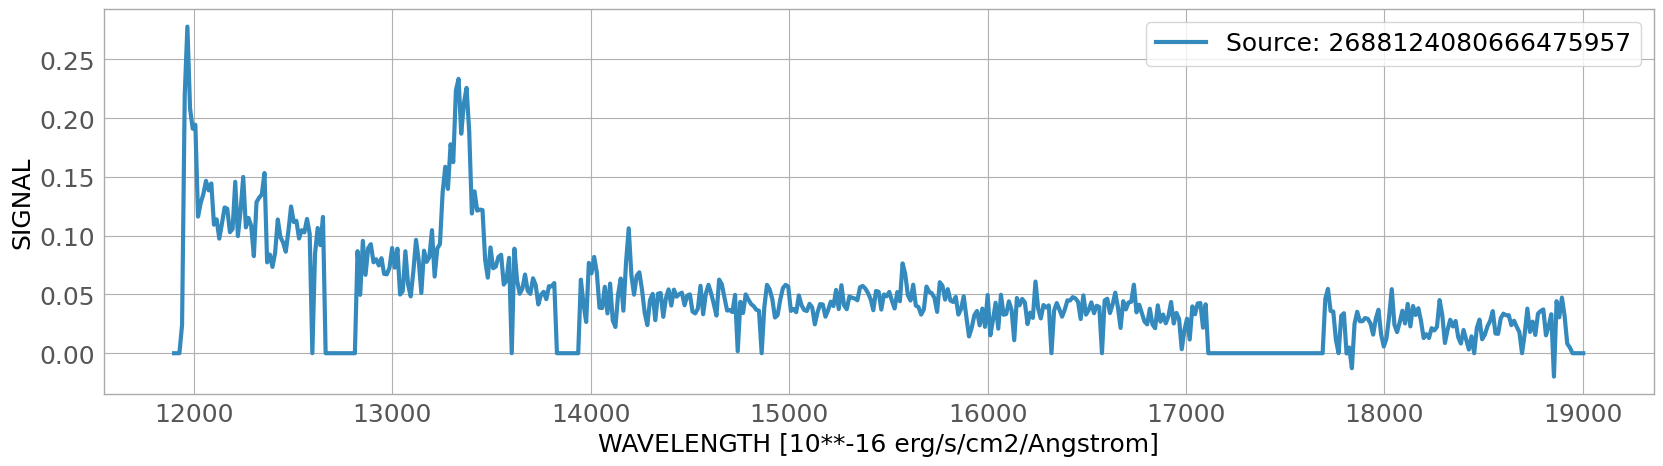

In [16]:
row_index    = 0 # To read the 1t row.
row          = res[row_index]
path_to_fits = f"{row['datalabs_path']}/{row['file_name']}"
hdu_index    = row['hdu_index']

hdul      = fits.open(path_to_fits)
spec_data = hdul[hdu_index].data
spec_data = Table(spec_data)
spec_head = hdul[hdu_index].header

# Plot the spectra ==========================================
fontsize = 18
fig = plt.figure(figsize = [20,5])
plt.plot(spec_data['WAVELENGTH'], spec_data['SIGNAL'], linewidth = 3, label = f"Source: {row['source_id']}")
plt.xlabel(f"WAVELENGTH [{spec_head['TUNIT2']}]", fontsize = fontsize)
plt.ylabel('SIGNAL', fontsize = fontsize)
plt.xticks(fontsize = fontsize)
plt.yticks(fontsize = fontsize)
plt.legend(fontsize = fontsize)
plt.show()

## 8. User space management

Authenticated (registered) users:
* have access to all the [TAP+](https://astroquery.readthedocs.io/en/latest/gaia/gaia.html) capabilities (such as sharing tables, persistent jobs, and more), and 
* benefit from the the advantage of having the asynchronous jobs stored in the user area forever (until the user decides to remove them).

### 8.1 Async job management

All the asynchronous jobs launched by registered users are stored in the user area, which can store up to 10 GB of jobs.

#### 8.1.1 Async job deletion

It is recommended to remove unnecessary jobs to avoid filling up the user quota. The example below shows how to delete all the jobs in the user area using the list_async_jobs and remove_jobs methods.

In [17]:
job_ids = [job.jobid for job in Euclid.list_async_jobs()]

print(f'* Found {len(job_ids)} async jobs in the user area')

# Uncomment the line below to remove all the jobs
# Euclid.remove_jobs(job_ids)

* Found 283 async jobs in the user area


#### 8.1.2 Async job data & metadata

It is possible to retrieve the metadata (including the ADQL query) and data associated to a given job using the Euclid.load_async_job method. 

In [18]:
inp_job_id = job.jobid                                # Extracting the job launched in Sect.7, Step 1 above (Cell #14)
my_job     = Euclid.load_async_job(jobid=inp_job_id)
print(f'* ADQL Query associated to job: {inp_job_id}')
print()
print(my_job.parameters['query'])
print()

# Retrieve data associated to the job ==================
my_job_data = my_job.get_data()
print(f'* Job output contains {len(my_job_data)} rows - display the first 3 rows:')
my_job_data[0:3]

* ADQL Query associated to job: e650a83b-de8b-11f1-9c30-e8ebd3edb7d7-TPDR


                SELECT
                  
                  *,
                  DISTANCE(
                    POINT('ICRS', ra_obj, dec_obj),
                    POINT('ICRS', 268.8121672422664, 66.64761647418894)
                  ) AS dist
                FROM
                  dr1.spectra_source
                WHERE
                  1 = CONTAINS(
                    POINT('ICRS', ra_obj, dec_obj),
                    CIRCLE('ICRS', 268.8121672422664, 66.64761647418894, 0.0016666666666666668)
                  )
                ORDER BY
                  dist ASC
                

* Job output contains 19 rows - display the first 3 rows:


calblock_id_list,combined_spectra_fk,combined_spectra_product_fk,datalabs_path,dec_obj,dith_num,file_name,file_path,hdu_index,lambda_range,patch_id_list,ra_obj,source_id,sourcepatch_id,spectra_source_oid,to_be_published,dist
object,int64,int64,str55,float64,int64,str57,str65,int64,str3,int64,float64,int64,object,int64,int32,float64
['CALBLOCK-F-003'],6206,506809,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475957444824,3,EUC_SIR_W-COMBSPEC_102159486_20250823T144410.742623Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,804,RGS,99,268.812408005527,2688124080666475957,['268812408066647595799'],117140596,1,9.766042680420095e-05
['CALBLOCK-F-003'],6088,494875,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475992519604,4,EUC_SIR_W-COMBSPEC_102159486_20250823T152148.236419Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,785,RGS,151,268.812411149428,2688124111666475992,['2688124111666475992151'],114174169,1,9.820313870845445e-05
['CALBLOCK-F-003'],6163,502394,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,66.6475965298094,3,EUC_SIR_W-COMBSPEC_102159486_20250823T161507.209908Z.fits,/data/euclid/repository_dr1/DR1/R1/SIR_COMBINED_SPECTRA/102159486,667,RGS,57,268.812412213996,2688124122666475965,['268812412266647596557'],116048073,1,9.91302352068557e-05


### 8.2 User tables management

Registered users can store tables in their 10 GB user space. These tables are stored in the Archive database and, as explained in this related Gaia Archive FAQ [Why does my small (<150 MB) table not fit into my user space?](https://www.cosmos.esa.int/web/gaia/faqs#user_upload_table_size-2023) the actuall table size at the database will be larger than the originall table size.

#### 8.2.1 Listing all user tables and accessing them

It is possible to list all the user tables as explained below:

In [31]:
tables  = Euclid.load_tables(only_names=True, include_shared_tables=True)
utables = [table.get_qualified_name() for table in tables if 'user_' in table.get_qualified_name()]
utables

INFO: Retrieving tables... [astroquery.utils.tap.core]
INFO: Parsing tables... [astroquery.utils.tap.core]
INFO: Done. [astroquery.utils.tap.core]


['user_hcanovas.des_target_sources',
 'user_hcanovas.input_spec_list',
 'user_sascat.all_columns_for_sas']

The user tables can be queried via ADQL to download (or inspect) their content. 

In [20]:
if len(utables) == 0:
    print("The user has no tables.")
else:
    query = f'SELECT * FROM {utables[0]}'
    print(query)
    print()
    res  = Euclid.launch_job_async(query).get_results()
    display(res)

SELECT * FROM user_hcanovas.des_target_sources

INFO: Query finished. [astroquery.utils.tap.core]


des_target_sources_oid,Euclid_ID,DES_ID,right_ascension,declination
int32,float64,int64,float64,float64
19,--,1252665,52.551414,-28.045916
36,-5.231905312900241e+17,1255139,52.319019,-29.002293
40,-5.472330862935184e+17,1256432,54.723301,-29.351784
63,-5.3244656927250586e+17,1261163,53.244629,-27.250557
87,-5.344793032944104e+17,1263930,53.447895,-29.441017
107,-5.399317722950555e+17,1284601,53.993145,-29.505514
128,-5.238843072757117e+17,1293832,52.388416,-27.571123
154,-5.34389560296768e+17,1299775,53.438869,-29.6768
175,-5.309303722795458e+17,1304503,53.09301,-27.954535


#### 8.2.1 Upload a table to the user space

It is possible to upload a table to the user space directly from a asynchronous job, from an Astropy table, or from a file stored in your computer in various formats - Please see the Gaia Archive [Upload a user table](https://www.cosmos.esa.int/web/gaia-users/archive/collaborate#UploadUserTable) tutorial for more details (as both the Astroquery.Euclid and Astroquery.Gaia packages share the user management capabilities). 

The example below shows how to upload an Astropy table, re-using the table retrieved in the previous cell.

**Warnings:** 
* If the table name already exists in the user space the table upload will be stopped and an error will be raised.
* Dataframes are not supported; however, it is very easy to import/export dataframes as Astropy.table objects - see the [Interfacing with DataFrames](https://docs.astropy.org/en/latest/table/dataframes.html#df-narwhals) Astropy documentation for details.

In [32]:
query       = f"""SELECT right_ascension AS q1_ra, declination AS q1_dec, object_id AS q1_object_id
FROM q1.mer_catalogue
WHERE DISTANCE(267.78, 65.53, right_ascension, declination) < 0.1"""

test_table = Euclid.launch_job_async(query = query).get_results()
display(test_table)

table_name = 'my_q1_source_list'
utables_n  = [inp[inp.find('.')+1:] for inp in utables]

if table_name in utables_n:
    print(f'* The table {table_name} already exists in the user space - please try with a different name')
else:
    Euclid.upload_table(upload_resource=test_table, table_name=table_name, table_description='This table is generated by the Astroquery tutorial')

INFO: Query finished. [astroquery.utils.tap.core]


q1_ra,q1_dec,q1_object_id
deg,deg,NA
float64,float64,int64
267.76637337746735,65.43104746600787,2677663733654310474
267.7810588066067,65.43165104214243,2677810588654316510
267.75433366901154,65.43210003266003,2677543336654321000
267.73349196318406,65.43371228462766,2677334919654337122
267.8176019311206,65.43502412612516,2678176019654350241
267.8145908986291,65.43515542725535,2678145908654351554
267.844692859942,65.43519138788884,2678446928654351913
267.72916992775515,65.4359109954949,2677291699654359109


INFO: Sending pytable. [astroquery.utils.tap.core]
INFO: Uploaded table 'my_q1_source_list'. [astroquery.utils.tap.core]


#### 8.2.3 Delete a user table

In [33]:
# Uncomment below to delete the table example
# Euclid.delete_user_table(table_name=table_name)

### 8.3 Xmatch with a user table

The example below shows how to apply a basic positional cross-match between a user table (that contains 15,129 rows from Q1) VS the MER DEEP survey. The query finishes in a few seconds (depending on the Archive load).

In [34]:
query = f"""SELECT my_sample.*, dr1.*, DISTANCE(my_sample.q1_ra, my_sample.q1_dec, dr1.right_ascension, dr1.declination)*3600 AS separation_arcsec
FROM dr1.mer_catalogue_deep_survey AS dr1
JOIN user_{Euclid._TapPlus__user}.{table_name} AS my_sample
ON DISTANCE(my_sample.q1_ra, my_sample.q1_dec, dr1.right_ascension, dr1.declination) < 1./3600.
ORDER BY dr1.object_id ASC"""

print(query)

job = Euclid.launch_job_async(query, output_format='ecsv')
res = job.get_results()

print(f'* Output table contains {len(res)} - displaying TOP 3 rows')
res[0:3]

SELECT my_sample.*, dr1.*, DISTANCE(my_sample.q1_ra, my_sample.q1_dec, dr1.right_ascension, dr1.declination)*3600 AS separation_arcsec
FROM dr1.mer_catalogue_deep_survey AS dr1
JOIN user_hcanovas.my_q1_source_list AS my_sample
ON DISTANCE(my_sample.q1_ra, my_sample.q1_dec, dr1.right_ascension, dr1.declination) < 1./3600.
ORDER BY dr1.object_id ASC
INFO: Query finished. [astroquery.utils.tap.core]
* Output table contains 12744 - displaying TOP 3 rows


my_q1_source_list_oid,q1_ra,q1_dec,q1_object_id,designation,object_id,avg_trans_wave_g_ext_decam,avg_trans_wave_g_ext_hsc,avg_trans_wave_g_ext_jpcam,avg_trans_wave_g_ext_lsst,avg_trans_wave_h,avg_trans_wave_i_ext_decam,avg_trans_wave_i_ext_lsst,avg_trans_wave_i_ext_panstarrs,avg_trans_wave_j,avg_trans_wave_r_ext_decam,avg_trans_wave_r_ext_lsst,avg_trans_wave_r_ext_megacam,avg_trans_wave_u_ext_decam,avg_trans_wave_u_ext_lsst,avg_trans_wave_u_ext_megacam,avg_trans_wave_vis,avg_trans_wave_y,avg_trans_wave_z_ext_decam,avg_trans_wave_z_ext_hsc,avg_trans_wave_z_ext_lsst,avg_trans_wave_z_ext_panstarrs,basic_download_data_oid,binary_flag,blended_prob,calblock_id_list,catalogue_oid,data_set_release,data_set_release_part1,data_set_release_part2,data_set_release_part3,deblended_flag,declination,declination_psf_fitting,det_quality_flag,ellipticity,ellipticity_err,extended_flag,extended_prob,flag_g_ext_decam,flag_g_ext_hsc,flag_g_ext_jpcam,flag_g_ext_lsst,flag_h,flag_i_ext_decam,flag_i_ext_lsst,flag_i_ext_panstarrs,flag_j,flag_nir_stack,flag_r_ext_decam,flag_r_ext_lsst,flag_r_ext_megacam,flag_u_ext_decam,flag_u_ext_lsst,flag_u_ext_megacam,flag_vis,flag_y,flag_z_ext_decam,flag_z_ext_hsc,flag_z_ext_lsst,flag_z_ext_panstarrs,flux_detection_total,fluxerr_detection_total,fluxerr_g_ext_decam_1fwhm_aper,fluxerr_g_ext_decam_2fwhm_aper,fluxerr_g_ext_decam_3fwhm_aper,fluxerr_g_ext_decam_4fwhm_aper,fluxerr_g_ext_decam_disk_sersic,fluxerr_g_ext_decam_sersic,fluxerr_g_ext_decam_templfit,fluxerr_g_ext_hsc_1fwhm_aper,fluxerr_g_ext_hsc_2fwhm_aper,fluxerr_g_ext_hsc_3fwhm_aper,fluxerr_g_ext_hsc_4fwhm_aper,fluxerr_g_ext_hsc_disk_sersic,fluxerr_g_ext_hsc_sersic,fluxerr_g_ext_hsc_templfit,fluxerr_g_ext_jpcam_1fwhm_aper,fluxerr_g_ext_jpcam_2fwhm_aper,fluxerr_g_ext_jpcam_3fwhm_aper,fluxerr_g_ext_jpcam_4fwhm_aper,fluxerr_g_ext_jpcam_disk_sersic,fluxerr_g_ext_jpcam_sersic,fluxerr_g_ext_jpcam_templfit,fluxerr_g_ext_lsst_1fwhm_aper,fluxerr_g_ext_lsst_2fwhm_aper,fluxerr_g_ext_lsst_3fwhm_aper,fluxerr_g_ext_lsst_4fwhm_aper,fluxerr_g_ext_lsst_disk_sersic,fluxerr_g_ext_lsst_sersic,fluxerr_g_ext_lsst_templfit,fluxerr_h_1fwhm_aper,fluxerr_h_2fwhm_aper,fluxerr_h_3fwhm_aper,fluxerr_h_4fwhm_aper,fluxerr_h_disk_sersic,fluxerr_h_sersic,fluxerr_h_templfit,fluxerr_i_ext_decam_1fwhm_aper,fluxerr_i_ext_decam_2fwhm_aper,fluxerr_i_ext_decam_3fwhm_aper,fluxerr_i_ext_decam_4fwhm_aper,fluxerr_i_ext_decam_disk_sersic,fluxerr_i_ext_decam_sersic,fluxerr_i_ext_decam_templfit,fluxerr_i_ext_lsst_1fwhm_aper,fluxerr_i_ext_lsst_2fwhm_aper,fluxerr_i_ext_lsst_3fwhm_aper,fluxerr_i_ext_lsst_4fwhm_aper,fluxerr_i_ext_lsst_disk_sersic,fluxerr_i_ext_lsst_sersic,fluxerr_i_ext_lsst_templfit,fluxerr_i_ext_panstarrs_1fwhm_aper,fluxerr_i_ext_panstarrs_2fwhm_aper,fluxerr_i_ext_panstarrs_3fwhm_aper,fluxerr_i_ext_panstarrs_4fwhm_aper,fluxerr_i_ext_panstarrs_disk_sersic,fluxerr_i_ext_panstarrs_sersic,fluxerr_i_ext_panstarrs_templfit,fluxerr_j_1fwhm_aper,fluxerr_j_2fwhm_aper,fluxerr_j_3fwhm_aper,fluxerr_j_4fwhm_aper,fluxerr_j_disk_sersic,fluxerr_j_sersic,fluxerr_j_templfit,fluxerr_nir_stack_1fwhm_aper,fluxerr_nir_stack_2fwhm_aper,fluxerr_nir_stack_3fwhm_aper,fluxerr_nir_stack_4fwhm_aper,fluxerr_r_ext_decam_1fwhm_aper,fluxerr_r_ext_decam_2fwhm_aper,fluxerr_r_ext_decam_3fwhm_aper,fluxerr_r_ext_decam_4fwhm_aper,fluxerr_r_ext_decam_disk_sersic,fluxerr_r_ext_decam_sersic,fluxerr_r_ext_decam_templfit,fluxerr_r_ext_lsst_1fwhm_aper,fluxerr_r_ext_lsst_2fwhm_aper,fluxerr_r_ext_lsst_3fwhm_aper,fluxerr_r_ext_lsst_4fwhm_aper,fluxerr_r_ext_lsst_disk_sersic,fluxerr_r_ext_lsst_sersic,fluxerr_r_ext_lsst_templfit,fluxerr_r_ext_megacam_1fwhm_aper,fluxerr_r_ext_megacam_2fwhm_aper,fluxerr_r_ext_megacam_3fwhm_aper,fluxerr_r_ext_megacam_4fwhm_aper,fluxerr_r_ext_megacam_disk_sersic,fluxerr_r_ext_megacam_sersic,fluxerr_r_ext_megacam_templfit,fluxerr_segmentation,fluxerr_u_ext_decam_1fwhm_aper,fluxerr_u_ext_decam_2fwhm_aper,fluxerr_u_ext_decam_3fwhm_aper,fluxerr_u_ext_decam_4fwhm_aper,fluxerr_u_ext_decam_disk_sersic,fluxerr_u_ext_decam_se